# Sales Data Analysis

This project analyzes sales performance using the Superstore dataset.
We focus on revenue, profit, and business insights.

In [1]:
import pandas as pd

df = pd.read_csv("data/train.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed", dayfirst=True)
df["Month"] = df["Order Date"].dt.to_period("M")

df[["Order Date", "Month"]].head()

,Order Date,Month
0,2017-11-08,2017-11
1,2017-11-08,2017-11
2,2017-06-12,2017-06
3,2016-10-11,2016-10
4,2016-10-11,2016-10


## KPI Analysis

In this section, we calculate key business metrics (KPIs) such as total revenue, total profit, and top-performing regions and categories.

In [5]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Month'],
      dtype='str')


In [6]:
total_revenue = df["Sales"].sum()

top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_category = df.groupby("Category")["Sales"].sum().idxmax()

print("Total Revenue:", total_revenue)
print("Top Region:", top_region)
print("Top Category:", top_category)

Total Revenue: 2261536.7827
Top Region: West
Top Category: Technology


### Insights

- The total revenue is approximately 2.26 million.
- The West region is the top-performing region.
- Technology is the highest-selling category.

These insights can help guide business decisions such as focusing on high-performing regions and product categories.

In [7]:
monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales.head()

Month
2015-01    14205.707
2015-02     4519.892
2015-03    55205.797
2015-04    27906.855
2015-05    23644.303
Freq: M, Name: Sales, dtype: float64

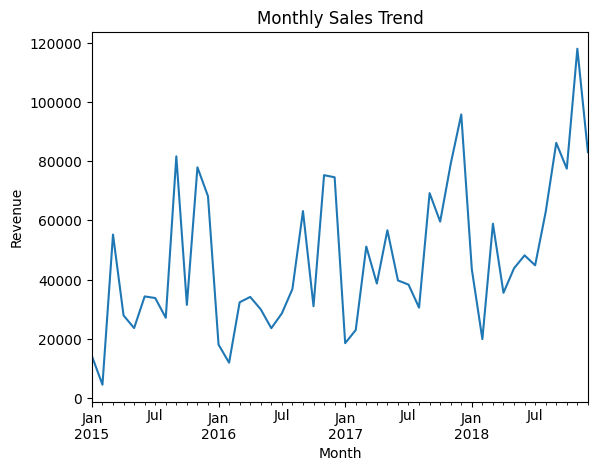

In [8]:
import matplotlib.pyplot as plt

monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

### Monthly Sales Trend Analysis

- Sales show an overall increasing trend over time, indicating business growth.
- There are noticeable fluctuations, suggesting variability in monthly performance.
- Recent months show higher peaks, which may indicate strong recent demand or expansion.

This trend analysis helps understand revenue behavior over time and supports future forecasting.

In [9]:
monthly_sales = monthly_sales.reset_index()
monthly_sales["Month"] = monthly_sales["Month"].astype(str)

monthly_sales.head()

,Month,Sales
0,2015-01,14205.707
1,2015-02,4519.892
2,2015-03,55205.797
3,2015-04,27906.855
4,2015-05,23644.303


In [10]:
monthly_sales["Month_num"] = range(len(monthly_sales))
monthly_sales.head()

,Month,Sales,Month_num
0,2015-01,14205.707,0
1,2015-02,4519.892,1
2,2015-03,55205.797,2
3,2015-04,27906.855,3
4,2015-05,23644.303,4


### Linear Regression Model

We use linear regression to model the relationship between time and sales.

This model assumes a linear trend in the data and provides a simple way to estimate future sales.

While it may not capture complex patterns such as seasonality, it serves as a strong baseline for forecasting.

In [11]:
from sklearn.linear_model import LinearRegression

X = monthly_sales[["Month_num"]]   # input (time)
y = monthly_sales["Sales"]         # output (sales)

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
import numpy as np

future_months = pd.DataFrame({
    "Month_num": range(len(monthly_sales), len(monthly_sales) + 12)
})

predictions = model.predict(future_months)

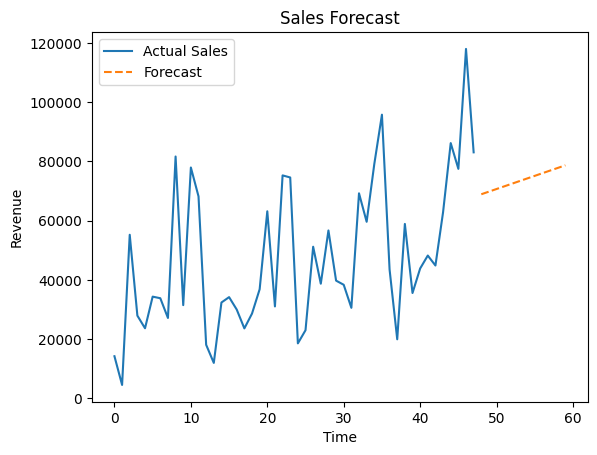

In [14]:
plt.figure()

plt.plot(monthly_sales["Month_num"], y, label="Actual Sales")
plt.plot(future_months["Month_num"], predictions, label="Forecast", linestyle="dashed")

plt.legend()
plt.title("Sales Forecast")
plt.xlabel("Time")
plt.ylabel("Revenue")

plt.show()

### Forecast Interpretation

The model predicts a steady increase in sales over time.

However, the forecast appears as a straight line because linear regression captures only the overall trend and does not account for fluctuations or seasonal patterns in the data.

This highlights a limitation of the model and suggests that more advanced time series models could improve accuracy.

In [15]:
monthly_sales["Smoothed_Sales"] = monthly_sales["Sales"].rolling(window=3).mean()

monthly_sales.head()

,Month,Sales,Month_num,Smoothed_Sales
0,2015-01,14205.707,0,NaN
1,2015-02,4519.892,1,NaN
2,2015-03,55205.797,2,24643.798667
3,2015-04,27906.855,3,29210.848000
4,2015-05,23644.303,4,35585.651667


In [16]:
monthly_sales = monthly_sales.dropna()

### Moving Average

A moving average is used to smooth short-term fluctuations in the data by averaging values over a fixed window.

This helps reveal the underlying trend and reduces noise in the data.

In [17]:
X = monthly_sales[["Month_num"]]
y = monthly_sales["Smoothed_Sales"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [18]:
future_months = pd.DataFrame({
    "Month_num": range(monthly_sales["Month_num"].max() + 1,
                       monthly_sales["Month_num"].max() + 13)
})

predictions = model.predict(future_months)

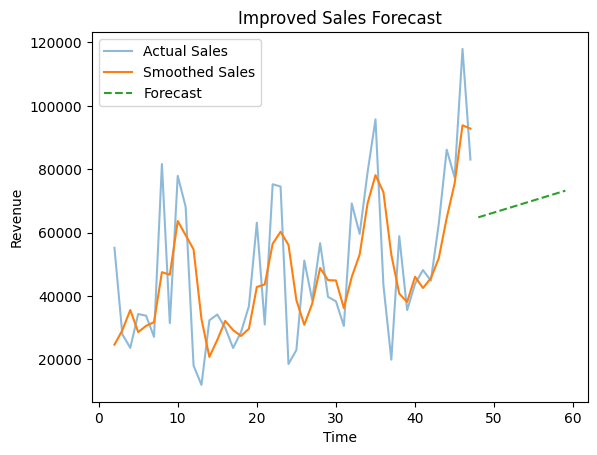

In [19]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(monthly_sales["Month_num"], monthly_sales["Sales"], label="Actual Sales", alpha=0.5)
plt.plot(monthly_sales["Month_num"], monthly_sales["Smoothed_Sales"], label="Smoothed Sales")
plt.plot(future_months["Month_num"], predictions, label="Forecast", linestyle="dashed")

plt.legend()
plt.title("Improved Sales Forecast")
plt.xlabel("Time")
plt.ylabel("Revenue")
plt.show()

In [20]:
monthly_sales["Month_num"].max() + 1

np.int64(48)

### Improved Forecast with Smoothing

To reduce short-term noise, a 3-month moving average was applied to sales data.

The forecasting model was then trained on the smoothed sales values instead of the raw monthly sales. This helps the model focus on the underlying trend rather than temporary fluctuations.

In [22]:
monthly_sales["Month"] = pd.to_datetime(monthly_sales["Month"])
monthly_sales["Month_of_year"] = monthly_sales["Month"].dt.month

### Adding Seasonality Features

To capture recurring monthly patterns, we extract the month of the year from each date.

This gives the model information about seasonality, allowing it to distinguish between months such as January, June, and December.

In [23]:
X = monthly_sales[["Month_num", "Month_of_year"]]
y = monthly_sales["Smoothed_Sales"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
X = monthly_sales[["Month_num", "Month_of_year"]]
y = monthly_sales["Smoothed_Sales"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [26]:
X = monthly_sales[["Month_num", "Month_of_year"]]
y = monthly_sales["Smoothed_Sales"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [27]:
future_months = pd.DataFrame({
    "Month_num": range(
        monthly_sales["Month_num"].max() + 1,
        monthly_sales["Month_num"].max() + 13
    )
})

future_months["Month_of_year"] = (future_months["Month_num"] % 12) + 1

future_months.head()

,Month_num,Month_of_year
0,48,1
1,49,2
2,50,3
3,51,4
4,52,5


In [28]:
predictions = model.predict(future_months)

In [29]:
last_month = monthly_sales["Month"].max()

future_dates = pd.date_range(
    start=last_month + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_months = pd.DataFrame({
    "Month_num": range(
        monthly_sales["Month_num"].max() + 1,
        monthly_sales["Month_num"].max() + 13
    ),
    "Month": future_dates
})

future_months["Month_of_year"] = future_months["Month"].dt.month

In [30]:
predictions = model.predict(future_months[["Month_num", "Month_of_year"]])

### Handling Seasonality in Future Predictions

To make seasonality-aware forecasts, future data must include the same features used during model training.

For this reason, both the time index (`Month_num`) and the calendar month (`Month_of_year`) are included in the future dataset before prediction.

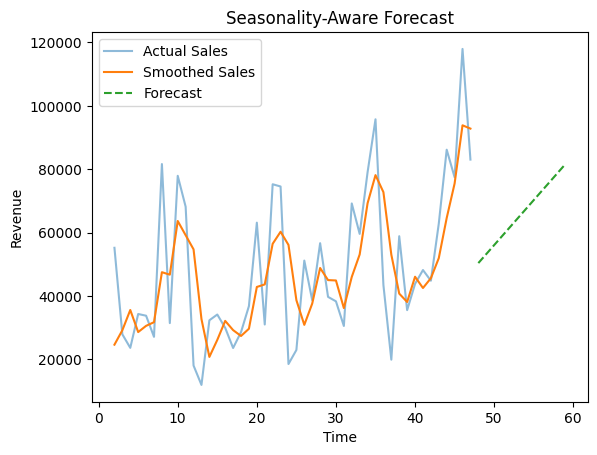

In [31]:
plt.figure()

plt.plot(monthly_sales["Month_num"], monthly_sales["Sales"], label="Actual Sales", alpha=0.5)
plt.plot(monthly_sales["Month_num"], monthly_sales["Smoothed_Sales"], label="Smoothed Sales")
plt.plot(future_months["Month_num"], predictions, label="Forecast", linestyle="dashed")

plt.legend()
plt.title("Seasonality-Aware Forecast")
plt.xlabel("Time")
plt.ylabel("Revenue")
plt.show()

### Interpreting the Seasonality-Aware Forecast

Although a month-of-year feature was added, the forecast still appears mostly linear.

This suggests that the model is still driven primarily by the long-term trend. A simple numeric month feature does not fully represent cyclical seasonal behavior, since months repeat in a loop rather than increasing in a straight line.

This highlights the need for better seasonality encoding or more advanced time-series models.

In [32]:
month_dummies = pd.get_dummies(monthly_sales["Month_of_year"], prefix="month", dtype=int)

X = pd.concat([monthly_sales[["Month_num"]], month_dummies], axis=1)
y = monthly_sales["Smoothed_Sales"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [33]:
last_month = monthly_sales["Month"].max()

future_dates = pd.date_range(
    start=last_month + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_months = pd.DataFrame({
    "Month_num": range(
        monthly_sales["Month_num"].max() + 1,
        monthly_sales["Month_num"].max() + 13
    ),
    "Month": future_dates
})

future_months["Month_of_year"] = future_months["Month"].dt.month

In [34]:
future_dummies = pd.get_dummies(future_months["Month_of_year"], prefix="month", dtype=int)
future_dummies = future_dummies.reindex(columns=month_dummies.columns, fill_value=0)

X_future = pd.concat([future_months[["Month_num"]], future_dummies], axis=1)

predictions = model.predict(X_future)

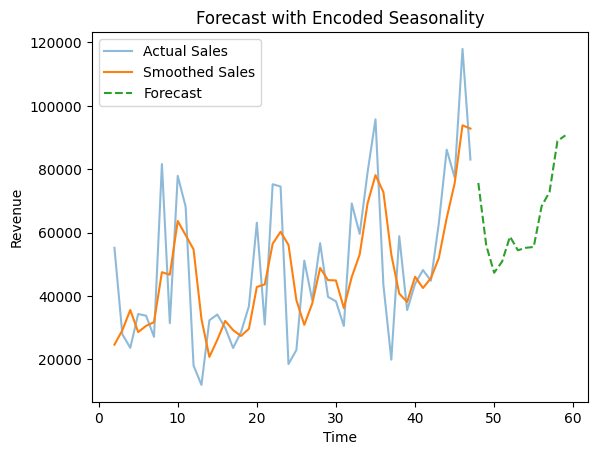

In [35]:
plt.figure()

plt.plot(monthly_sales["Month_num"], monthly_sales["Sales"], label="Actual Sales", alpha=0.5)
plt.plot(monthly_sales["Month_num"], monthly_sales["Smoothed_Sales"], label="Smoothed Sales")
plt.plot(future_months["Month_num"], predictions, label="Forecast", linestyle="dashed")

plt.legend()
plt.title("Forecast with Encoded Seasonality")
plt.xlabel("Time")
plt.ylabel("Revenue")
plt.show()

### Forecast with Encoded Seasonality

To better capture seasonal patterns, the month of the year was encoded using one-hot encoding.

This allows the model to assign different effects to each month, rather than treating months as a simple numeric sequence.

As a result, the forecast now reflects both long-term trends and recurring seasonal fluctuations.

In [36]:
from sklearn.metrics import mean_absolute_error

y_pred_train = model.predict(X)

mae = mean_absolute_error(y, y_pred_train)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 4877.129700067095


### Model Evaluation

The model was evaluated using Mean Absolute Error (MAE), which measures the average difference between predicted and actual values.

The MAE obtained is approximately 4,877, indicating that predictions deviate from actual sales by this amount on average.

Since this evaluation is performed on the training data, the result may be optimistic. A more reliable assessment requires testing the model on unseen data.

### Train-Test Evaluation

To evaluate the model more realistically, the data is split into training and testing sets.

The model is trained on earlier time periods and tested on later periods, which better reflects how forecasting works in real business scenarios.

In [37]:
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 36
Testing samples: 10


In [38]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [39]:
y_pred = model.predict(X_test)

In [40]:
from sklearn.metrics import mean_absolute_error

test_mae = mean_absolute_error(y_test, y_pred)
print("Test MAE:", test_mae)

Test MAE: 8430.668915555552


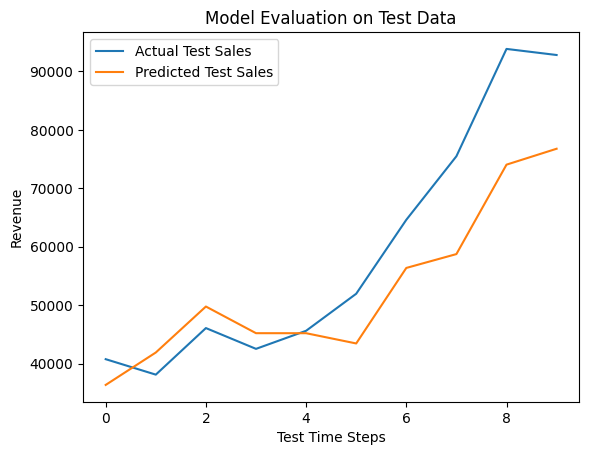

In [41]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(range(len(y_test)), y_test.values, label="Actual Test Sales")
plt.plot(range(len(y_test)), y_pred, label="Predicted Test Sales")

plt.legend()
plt.title("Model Evaluation on Test Data")
plt.xlabel("Test Time Steps")
plt.ylabel("Revenue")
plt.show()

### Seasonality Encoding

To better capture seasonal patterns, cyclical features were created using sine and cosine transformations of the month.

This allows the model to understand that months repeat in cycles (e.g., December is close to January), improving forecasting performance.

In [42]:
import numpy as np

monthly_sales["Month_sin"] = np.sin(2 * np.pi * monthly_sales["Month_of_year"] / 12)
monthly_sales["Month_cos"] = np.cos(2 * np.pi * monthly_sales["Month_of_year"] / 12)

monthly_sales.head()

,Month,Sales,Month_num,Smoothed_Sales,Month_of_year,Month_sin,Month_cos
2,2015-03-01,55205.7970,2,24643.798667,3,1.000000e+00,6.123234e-17
3,2015-04-01,27906.8550,3,29210.848000,4,8.660254e-01,-5.000000e-01
4,2015-05-01,23644.3030,4,35585.651667,5,5.000000e-01,-8.660254e-01
5,2015-06-01,34322.9356,5,28624.697867,6,1.224647e-16,-1.000000e+00
6,2015-07-01,33781.5430,6,30582.927200,7,-5.000000e-01,-8.660254e-01


In [44]:
X = monthly_sales[["Month_num", "Month_sin", "Month_cos"]]
y = monthly_sales["Smoothed_Sales"]

In [45]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [46]:
future_months = np.arange(len(monthly_sales), len(monthly_sales) + 12)

future_df = pd.DataFrame({
    "Month_num": future_months
})

future_df["Month_of_year"] = (future_df["Month_num"] % 12) + 1

future_df["Month_sin"] = np.sin(2 * np.pi * future_df["Month_of_year"] / 12)
future_df["Month_cos"] = np.cos(2 * np.pi * future_df["Month_of_year"] / 12)

In [47]:
predictions = model.predict(future_df[["Month_num", "Month_sin", "Month_cos"]])

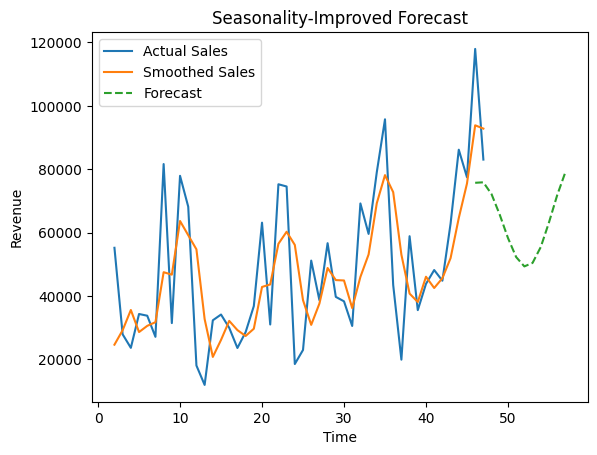

In [48]:
plt.figure()

plt.plot(monthly_sales["Month_num"], monthly_sales["Sales"], label="Actual Sales")
plt.plot(monthly_sales["Month_num"], monthly_sales["Smoothed_Sales"], label="Smoothed Sales")

plt.plot(future_df["Month_num"], predictions, label="Forecast", linestyle="dashed")

plt.legend()
plt.title("Seasonality-Improved Forecast")
plt.xlabel("Time")
plt.ylabel("Revenue")
plt.show()

## Conclusion

In this project, we analyzed historical sales data and built a forecasting model to predict future revenue.

We started with basic data exploration and KPI analysis, then modeled the trend using linear regression. To improve performance, we applied smoothing techniques and introduced seasonality encoding using sine and cosine transformations.

The final model captures both trend and seasonal patterns, providing a more realistic forecast of future sales.

While the model remains simple, it demonstrates key concepts in time series analysis and serves as a strong baseline for further improvements.